Final Test log-MSE score for MLP: 0.1224
Final Test log-RMSE score for MLP: 0.3499
Final Test R2 score for MLP: 0.8639
Final Test log-MSE score for SVR: 0.1213
Final Test log-RMSE score for SVR: 0.3482
Final Test R2 score for SVR: 0.8651


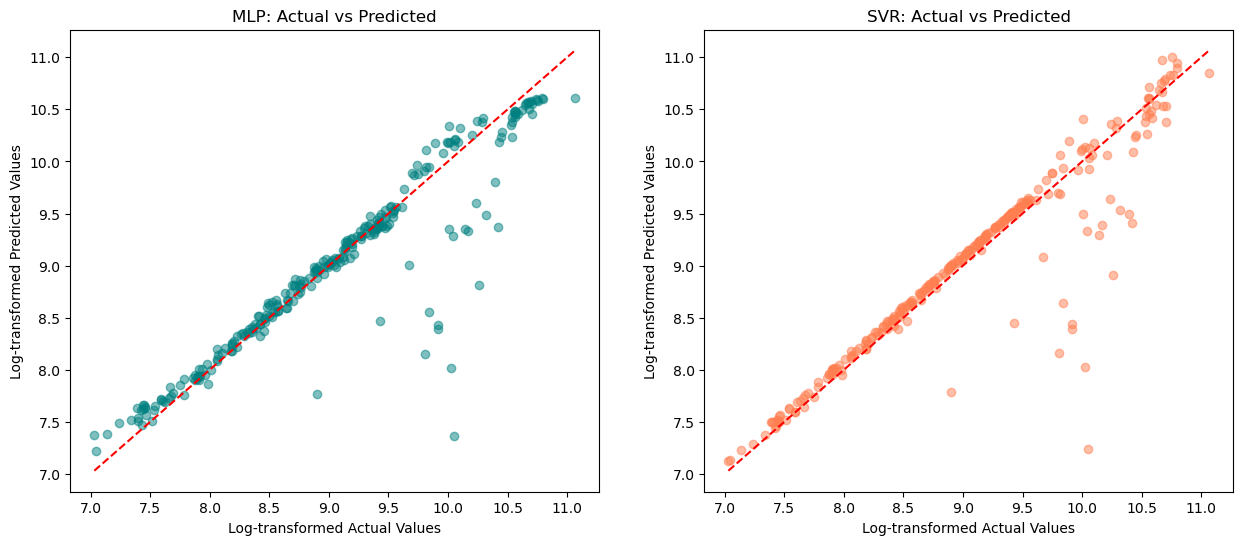

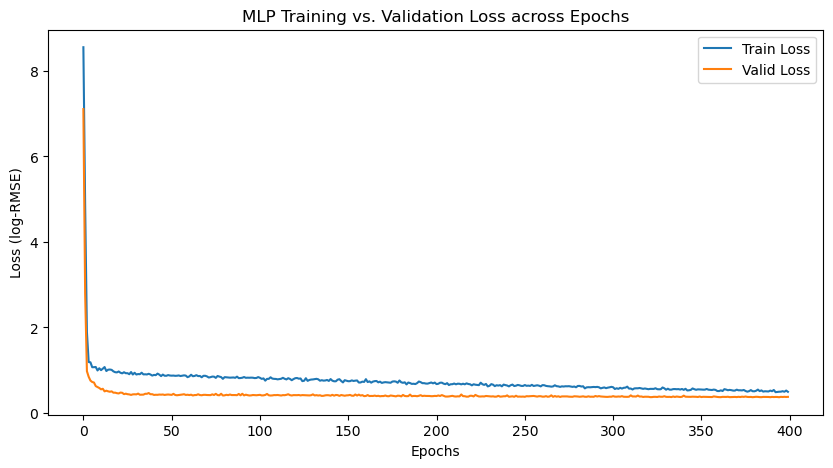

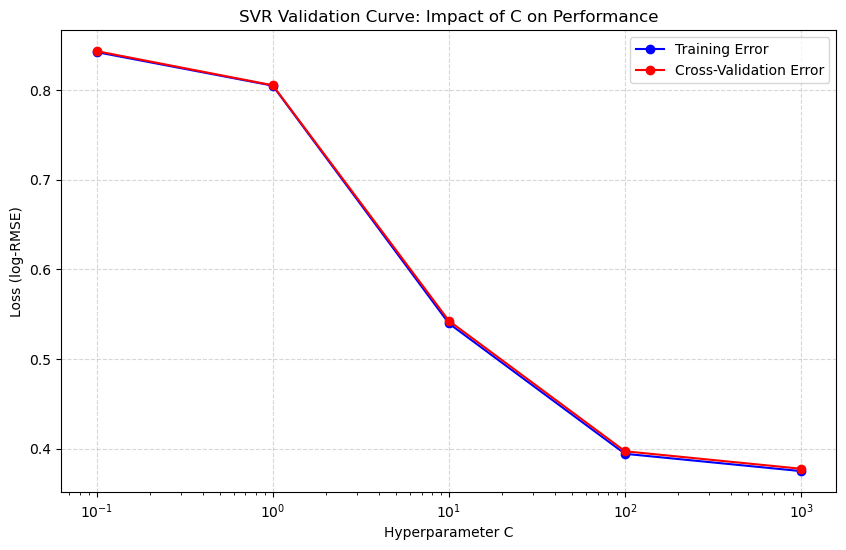

In [1]:
# Import relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
import torch
import torch.nn as nn
from sklearn.metrics import root_mean_squared_error, mean_squared_error, r2_score

# The MLP classes must match mlp_vs_svr.ipynb so the pickled skorch model can be loaded
class RMSELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss()
        
    def forward(self, yhat, y):
        return torch.sqrt(self.mse(yhat, y))
    
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, activation, num_layers, dropout):
        super().__init__()
        self.activation = activation()
        self.dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList()
        self.layers.append(nn.Linear(input_dim, hidden_dim))
        for _ in range(num_layers - 1):
            self.layers.append(nn.Linear(hidden_dim, hidden_dim))
        self.output_layer = nn.Linear(hidden_dim, 1)
           
    def forward(self, x):
        for layer in self.layers:
            x = self.activation(layer(x))
            x = self.dropout(x)
        x = self.output_layer(x)
        return x

# Load the preprocessed Test data
X_test = pd.read_csv("X_test.csv").values.astype('float32')
y_test = pd.read_csv("y_test.csv").values.astype('float32').reshape(-1, 1)

# Load the saved models
with open('best_mlp_model.pkl', 'rb') as f:
    loaded_mlp = pickle.load(f)

with open('best_svr_model.pkl', 'rb') as f:
    loaded_svr = pickle.load(f)

# Run Predictions
y_pred_mlp = loaded_mlp.predict(X_test)
y_pred_svr = loaded_svr.predict(X_test)

# Calculate metrics
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
rmse_mlp = root_mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = root_mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)

# Print final test scores
print(f"Final Test log-MSE score for MLP: {mse_mlp:.4f}")
print(f"Final Test log-RMSE score for MLP: {rmse_mlp:.4f}")
print(f"Final Test R2 score for MLP: {r2_mlp:.4f}")
print(f"Final Test log-MSE score for SVR: {mse_svr:.4f}")
print(f"Final Test log-RMSE score for SVR: {rmse_svr:.4f}")
print(f"Final Test R2 score for SVR: {r2_svr:.4f}")

# Visualisation 1: Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# MLP Plot
axes[0].scatter(y_test, y_pred_mlp, alpha=0.5, color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_title('MLP: Actual vs Predicted')
axes[0].set_xlabel('Log-transformed Actual Values')
axes[0].set_ylabel('Log-transformed Predicted Values')

# SVR Plot
axes[1].scatter(y_test, y_pred_svr, alpha=0.5, color='coral')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_title('SVR: Actual vs Predicted')
axes[1].set_xlabel('Log-transformed Actual Values')
axes[1].set_ylabel('Log-transformed Predicted Values')
plt.show()

# Visualisation 2: MLP Loss Curve
history = loaded_mlp.named_steps['mlp'].history
plt.figure(figsize=(10, 5))
plt.plot(history[:, 'train_loss'], label='Train Loss')
plt.plot(history[:, 'valid_loss'], label='Valid Loss')
plt.title('MLP Training vs. Validation Loss across Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (log-RMSE)')
plt.legend()
plt.show()

# Visualisation 3: SVR Validation Curve
validation_curve_data = pd.read_csv("svr_validation_curve_data.csv")

plt.figure(figsize=(10, 6))
plt.plot(validation_curve_data['param_range'], validation_curve_data['train_mean'], 
         label="Training Error", color="blue", marker='o')
plt.plot(validation_curve_data['param_range'], validation_curve_data['test_mean'], 
         label="Cross-Validation Error", color="red", marker='o')

plt.xscale('log')
plt.xlabel('Hyperparameter C')
plt.ylabel('Loss (log-RMSE)')
plt.title('SVR Validation Curve: Impact of C on Performance')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()